# Assignment No. 2: Data Cleaning and Preprocessing

**Name:** Zainab Arshad
**Roll No.:** 013
**Section:** 3A
**Dataset:** Melbourne Housing Snapshot (Kaggle)
**Link:** https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot

## 0. Setup (libraries and data path)

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

In [2]:
for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/dansbecker/melbourne-housing-snapshot/melb_data.csv


In [3]:
df_raw = pd.read_csv("/kaggle/input/datasets/dansbecker/melbourne-housing-snapshot/melb_data.csv")
df = df_raw.copy()
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (13580, 21)


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  object 
 6   SellerG        13580 non-null  object 
 7   Date           13580 non-null  object 
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  object 
 17  Lattitude      13580 non-null  float64
 18  Longti

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rooms,13580.0,2.937997e+00,0.955748,1.00000,2.000000,3.000000,3.000000e+00,1.000000e+01
Price,13580.0,1.075684e+06,639310.724296,85000.00000,650000.000000,903000.000000,1.330000e+06,9.000000e+06
Distance,13580.0,1.013778e+01,5.868725,0.00000,6.100000,9.200000,1.300000e+01,4.810000e+01
Postcode,13580.0,3.105302e+03,90.676964,3000.00000,3044.000000,3084.000000,3.148000e+03,3.977000e+03
Bedroom2,13580.0,2.914728e+00,0.965921,0.00000,2.000000,3.000000,3.000000e+00,2.000000e+01
Bathroom,13580.0,1.534242e+00,0.691712,0.00000,1.000000,1.000000,2.000000e+00,8.000000e+00
Car,13518.0,1.610075e+00,0.962634,0.00000,1.000000,2.000000,2.000000e+00,1.000000e+01
Landsize,13580.0,5.584161e+02,3990.669241,0.00000,177.000000,440.000000,6.510000e+02,4.330140e+05
BuildingArea,7130.0,1.519676e+02,541.014538,0.00000,93.000000,126.000000,1.740000e+02,4.451500e+04
YearBuilt,8205.0,1.964684e+03,37.273762,1196.00000,1940.000000,1970.000000,1.999000e+03,2.018000e+03


- **Title:** Melbourne Housing Snapshot
- **Source:** https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot (file: melb_data.csv)
- **Rows:** 13,580 | **Columns:** 21
- **Main columns:** Suburb, Address, Rooms, Type, Price, Method, SellerG, Date, Distance, Postcode, Bedroom2, Bathroom, Car, Landsize, BuildingArea, YearBuilt, CouncilArea, Latitude, Longitude, Regionname, Propertycount
- **Objective:** The dataset contains house sale records from Melbourne, Australia. The goal is to prepare the data so that the sale Price of a property can be predicted (regression).

**Interpretation:** `df.info()` shows that most columns are complete, but BuildingArea (7,130 non-null), YearBuilt (8,205 non-null), CouncilArea (12,211 non-null) and Car (13,518 non-null) have fewer values than the 13,580 rows, so they contain missing values. Date is stored as text (object), and Postcode, Bedroom2, Bathroom, Car and YearBuilt are stored as floats, so data types need correction. `df.describe()` shows very large maximum values in Landsize and BuildingArea compared with their medians, which suggests outliers.

## 2. Data Cleaning

In [6]:
df = df.rename(columns={"Lattitude": "Latitude", "Longtitude": "Longitude"})
df.columns.tolist()

['Suburb',
 'Address',
 'Rooms',
 'Type',
 'Price',
 'Method',
 'SellerG',
 'Date',
 'Distance',
 'Postcode',
 'Bedroom2',
 'Bathroom',
 'Car',
 'Landsize',
 'BuildingArea',
 'YearBuilt',
 'CouncilArea',
 'Latitude',
 'Longitude',
 'Regionname',
 'Propertycount']

### 2.1 Column Names

**Problem found:** Two column names are misspelled in the source data: `Lattitude` and `Longtitude`.

**Method applied:** The columns were renamed to `Latitude` and `Longitude` with `rename()`.

**Why:** Correct names avoid mistakes later in the code and make the dataset easier to understand.

In [7]:
miss = pd.DataFrame({"missing": df.isna().sum(),
                     "percent": (df.isna().mean() * 100).round(2)})
miss = miss[miss.missing > 0].sort_values("percent", ascending=False)
miss

,missing,percent
BuildingArea,6450,47.50
YearBuilt,5375,39.58
CouncilArea,1369,10.08
Car,62,0.46


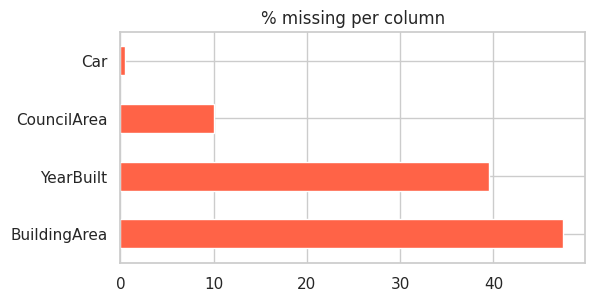

In [8]:
miss["percent"].plot.barh(figsize=(6, 3), color="tomato", title="% missing per column")
plt.show()

In [9]:
df["CouncilArea"] = df["CouncilArea"].fillna("Unknown")

### 2.2 Missing Values

**Problem found:** BuildingArea (about 47%), YearBuilt (about 40%), CouncilArea (about 10%) and Car (less than 1%) contain missing values.

**Method applied:** CouncilArea was filled with the constant label "Unknown". The numeric columns (BuildingArea, YearBuilt, Car) will be filled with the median later, after the train/test split.

**Why:** Rows cannot be dropped because BuildingArea and YearBuilt are missing in a large share of the data, so too much information would be lost. CouncilArea is categorical, so a constant label works. The median is used for numeric columns because it is not affected by extreme values. It is calculated only on the training set to avoid data leakage.

In [10]:
print("Fully duplicated rows      :", df.duplicated().sum())
print("Same Address + Date + Price:", df.duplicated(subset=["Address", "Date", "Price"]).sum())

Fully duplicated rows      : 0
Same Address + Date + Price: 1


In [11]:
before = len(df)
df = df.drop_duplicates(subset=["Address", "Date", "Price"]).reset_index(drop=True)
print("Rows before:", before, "| after:", len(df), "| removed:", before - len(df))

Rows before: 13580 | after: 13579 | removed: 1


### 2.3 Duplicate Records

**Problem found:** 1 duplicate record was found (same Address, Date and Price).

**Method applied:** `drop_duplicates()` was used and the first occurrence was kept.

**Why:** The same property cannot be sold at the same address, on the same day, for the same price twice. Duplicates can bias the model. Rows reduced from 13,580 to 13,579.

In [12]:
text_cols = df.select_dtypes(include=["object", "string"]).columns
for c in text_cols:
    df[c] = df[c].astype("string").str.strip()

df["Suburb"] = df["Suburb"].str.title()
df["Regionname"] = df["Regionname"].str.title()

In [13]:
df["Type"] = df["Type"].map({"h": "house", "u": "unit", "t": "townhouse"})

In [14]:
for c in ["Type", "Method", "Regionname"]:
    print("---", c, "---")
    print(df[c].value_counts(dropna=False), "\n")
print("Unique CouncilArea:", df["CouncilArea"].nunique())

--- Type ---
Type
house        9449
unit         3017
townhouse    1113
Name: count, dtype: int64 

--- Method ---
Method
S     9022
SP    1703
PI    1563
VB    1199
SA      92
Name: count, dtype: Int64 

--- Regionname ---
Regionname
Southern Metropolitan         4695
Northern Metropolitan         3889
Western Metropolitan          2948
Eastern Metropolitan          1471
South-Eastern Metropolitan     450
Eastern Victoria                53
Northern Victoria               41
Western Victoria                32
Name: count, dtype: Int64 

Unique CouncilArea: 34


### 2.4 Inconsistent Values / Categories

**Problem found:** Text columns can contain extra spaces or different capitalisation, and the Type column used one-letter codes (h, u, t) that are hard to read.

**Method applied:**
- Removed extra spaces from all text columns using `str.strip()`.
- Standardised capitalisation of Suburb and Regionname using `str.title()`.
- Mapped the Type codes to readable labels: h = house, u = unit, t = townhouse.

**Why this method:** If the same category is written in two ways (for example "Northern Metropolitan" and "northern metropolitan"), encoding would treat them as two different categories and split the data. Readable labels also make the results easier to understand.

**Result:** `value_counts()` showed no duplicated categories.
- Type has 3 categories: house (9449), unit (3017) and townhouse (1113). The total is 13,579, which equals the number of rows, so no value was lost in the mapping.
- Regionname has 8 clean categories.
- Method has 5 valid codes (S, SP, PI, VB, SA). These are official abbreviations, so they were kept as they are.
- CouncilArea has 34 unique values, including the "Unknown" label added earlier.

In [15]:
print(df[["Date", "Postcode", "Bedroom2", "Bathroom", "Car", "YearBuilt"]].dtypes)

Date         string[python]
Postcode            float64
Bedroom2            float64
Bathroom            float64
Car                 float64
YearBuilt           float64
dtype: object


In [16]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df["Postcode"] = df["Postcode"].astype(int).astype(str)
for c in ["Bedroom2", "Bathroom", "Car", "YearBuilt"]:
    df[c] = df[c].round().astype("Int64")

print(df[["Date", "Postcode", "Bedroom2", "Bathroom", "Car", "YearBuilt"]].dtypes)

Date         datetime64[ns]
Postcode             object
Bedroom2              Int64
Bathroom              Int64
Car                   Int64
YearBuilt             Int64
dtype: object


### 2.5 Data Types

**Problem found:** Date was stored as text. Postcode was a float, although it is an identifier. Bedroom2, Bathroom, Car and YearBuilt were floats (e.g. 2.0), although they are counts and years.

**Method applied:** Date was converted with `pd.to_datetime(dayfirst=True)`. Postcode was converted to string. The four count/year columns were converted to the nullable integer type `Int64`.

**Why:** A datetime column allows extracting year and month. Postcode is a label, so averaging or adding it has no meaning. Counts and years cannot be fractional. `Int64` (capital I) is used because it can hold missing values, which a normal `int` cannot. `dayfirst=True` was needed because the dates are in day/month/year format.

**Result:** Date is now datetime64, Postcode is object (string), and Bedroom2, Bathroom, Car and YearBuilt are Int64.

In [17]:
checks = {
    "YearBuilt < 1800":          (df["YearBuilt"] < 1800).sum(),
    "YearBuilt after sale year": (df["YearBuilt"] > df["Date"].dt.year).sum(),
    "BuildingArea == 0":         (df["BuildingArea"] == 0).sum(),
    "Price <= 0":                (df["Price"] <= 0).sum(),
    "Landsize == 0":             (df["Landsize"] == 0).sum(),
}
pd.Series(checks, name="count")

YearBuilt < 1800                1
YearBuilt after sale year       6
BuildingArea == 0              17
Price <= 0                      0
Landsize == 0                1939
Name: count, dtype: int64

In [18]:
df.loc[(df["YearBuilt"] < 1800) | (df["YearBuilt"] > df["Date"].dt.year), "YearBuilt"] = pd.NA
df.loc[df["BuildingArea"] <= 0, "BuildingArea"] = np.nan
df = df[df["Price"] > 0]
print("Rows now:", len(df))

Rows now: 13579


### 2.6 Impossible / Invalid Values

**Problem found:** Some values are physically impossible:
- YearBuilt before 1800: 1 record (e.g. a house built in the year 1196).
- YearBuilt later than the sale year: 6 records (a house cannot be sold before it was built).
- BuildingArea equal to 0: 17 records (a building cannot have zero area).
- Price less than or equal to 0: 0 records (no problem found).
- Landsize equal to 0: 1,939 records.

**Method applied:** The impossible YearBuilt values (7 records in total) and the BuildingArea values equal to 0 were replaced with missing values (NaN) instead of deleting the rows. A filter for Price <= 0 was applied, but it removed nothing, so the number of rows stayed at 13,579.

**Why this method:** These values are data-entry errors, so they cannot be trusted. Deleting the whole row would also throw away useful information in the other columns (price, rooms, location). Setting them to NaN keeps the row, and the value will be filled later with the median inside the pipeline (fitted on the training set only, to avoid data leakage).

**Landsize = 0 was NOT treated as an error:** Units and townhouses often have no private land of their own, so 0 is a real value. These rows were kept, and a binary flag feature (LandsizeZero) will be created later in feature engineering.

In [19]:
num_check = ["Price", "Distance", "Landsize", "BuildingArea", "Propertycount"]

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.Series({c: iqr_outliers(df[c].dropna().astype(float)) for c in num_check}, name="IQR outliers")

Price            612
Distance         411
Landsize         368
BuildingArea     353
Propertycount    359
Name: IQR outliers, dtype: int64

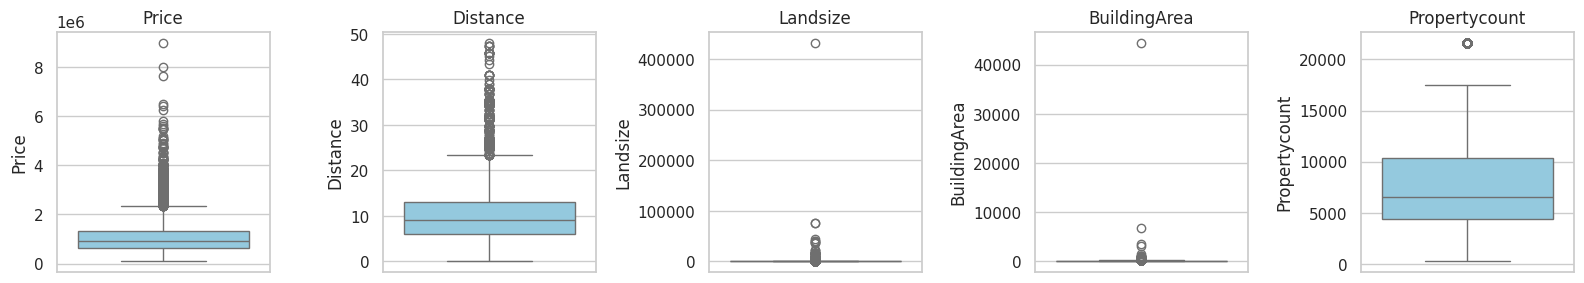

In [20]:
fig, axes = plt.subplots(1, len(num_check), figsize=(16, 3))
for ax, c in zip(axes, num_check):
    sns.boxplot(y=df[c].astype(float), ax=ax, color="skyblue")
    ax.set_title(c)
plt.tight_layout()
plt.show()

### 2.7 Outliers

**Problem found:** Boxplots and the IQR rule (values below Q1 - 1.5×IQR or above Q3 + 1.5×IQR) were used on Price, Distance, Landsize, BuildingArea and Propertycount.
- Price: 612 outliers
- Distance: 411 outliers
- Landsize: 368 outliers
- BuildingArea: 353 outliers
- Propertycount: 359 outliers

The boxplots show that Price and Distance have many high values, which are real (expensive or far-away properties). Landsize has one extreme value of about 430,000 and BuildingArea has one of about 44,000, which are likely data-entry errors.

**Method applied:** No rows were deleted at this stage. Outliers will be handled later by winsorizing (capping) each numeric feature at the 1st and 99th percentile of the training set. Price is not capped; its skewness is handled with a log transformation.

**Why this method:** Most extreme values are genuine (for example, a luxury house on a large block), so deleting them would remove valid information and bias the model. Capping keeps every row but stops a few extreme values from dominating. The percentiles are learned from the data, so they are computed on the training set only (after the split) to avoid data leakage.

## 3. Data Preprocessing

### 3.1 Features, Target and Variable Types

**Target:** Price (regression problem)

| Variable type | Columns |
|---|---|
| Numerical (continuous) | Distance, Landsize, BuildingArea, Latitude, Longitude, Propertycount, HouseAge, BathPerRoom |
| Numerical (counts / year) | Rooms, Bedroom2, Bathroom, Car, SaleYear |
| Binary | LandsizeZero, BuildingAreaMissing, YearBuiltMissing |
| Ordinal | AgeGroup (New < Modern < Established < Historic) |
| Nominal (categorical) | Type, Method, Regionname, CouncilArea, Suburb, SellerG |
| Date/time | Date (split into SaleYear and SaleMonth) |
| Dropped | Address (unique ID), Postcode (redundant with Suburb) |

In [21]:
# Features from the date
df["SaleYear"]  = df["Date"].dt.year
df["SaleMonth"] = df["Date"].dt.month
df["Month_sin"] = np.sin(2 * np.pi * df["SaleMonth"] / 12)
df["Month_cos"] = np.cos(2 * np.pi * df["SaleMonth"] / 12)

# New numeric features
df["HouseAge"]    = (df["SaleYear"] - df["YearBuilt"]).astype("float")
df["BathPerRoom"] = df["Bathroom"].astype("float") / df["Rooms"]

# Binary flags
df["LandsizeZero"]        = (df["Landsize"] == 0).astype(int)
df["BuildingAreaMissing"] = df["BuildingArea"].isna().astype(int)
df["YearBuiltMissing"]    = df["YearBuilt"].isna().astype(int)

# Ordinal feature (fixed bins, not learned from data)
age_order = ["New", "Modern", "Established", "Historic"]
df["AgeGroup"] = pd.cut(df["HouseAge"], bins=[-1, 10, 30, 70, np.inf], labels=age_order)
df["AgeGroup"] = df["AgeGroup"].astype("object")

df[["SaleYear", "SaleMonth", "HouseAge", "BathPerRoom", "LandsizeZero", "AgeGroup"]].head()

,SaleYear,SaleMonth,HouseAge,BathPerRoom,LandsizeZero,AgeGroup
0,2016,12,NaN,0.500000,0,NaN
1,2016,2,116.0,0.500000,0,Historic
2,2017,3,117.0,0.666667,0,Historic
3,2017,3,NaN,0.666667,0,NaN
4,2016,6,2.0,0.250000,0,New


### 3.2 Feature Engineering

**Features created:**
- SaleYear, SaleMonth: extracted from Date.
- Month_sin, Month_cos: sine/cosine encoding of the month, so that December and January are treated as neighbours.
- HouseAge = SaleYear - YearBuilt: the age of the house at the time of sale, which is usually more useful for price than the build year.
- BathPerRoom = Bathroom / Rooms: a simple comfort indicator.
- LandsizeZero, BuildingAreaMissing, YearBuiltMissing: binary flags. A zero land size usually means a unit, and the pattern of missing values can itself carry information.
- AgeGroup: an ordinal feature (New < Modern < Established < Historic) created with fixed age bins.

**Why before the split:** each feature uses only the values of its own row, no dataset-wide statistic is learned, so there is no data leakage.

Price skewness (raw)  : 2.24
Price skewness (log1p): 0.18


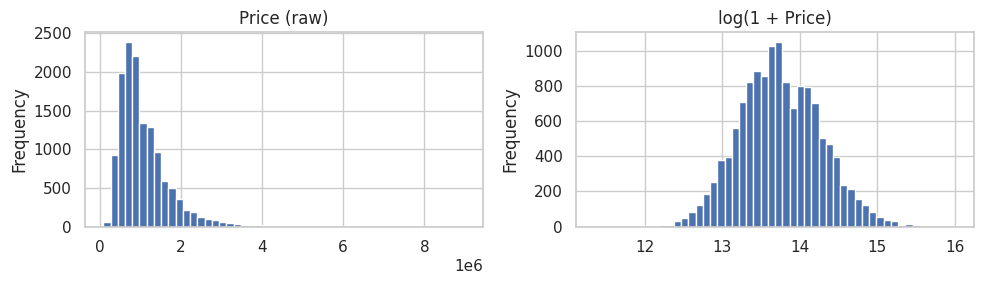

X shape: (13579, 26)


In [22]:
target = "Price"
drop_cols = ["Address", "Postcode", "Date", "SaleMonth", "Price"]

X = df.drop(columns=drop_cols)
y_raw = df[target].astype(float)

print("Price skewness (raw)  :", round(y_raw.skew(), 2))
y = np.log1p(y_raw)
print("Price skewness (log1p):", round(y.skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
y_raw.plot.hist(bins=50, ax=ax[0], title="Price (raw)")
y.plot.hist(bins=50, ax=ax[1], title="log(1 + Price)")
plt.tight_layout()
plt.show()

print("X shape:", X.shape)

### 3.3 Target, Features and Target Transformation

**Target:** Price. **Features (X):** 26 columns after dropping Address (unique ID), Postcode (redundant with Suburb), Date and SaleMonth (replaced by SaleYear, Month_sin and Month_cos) and the target itself.

**Problem found:** Price is strongly right-skewed (skewness = 2.24). A few very expensive properties pull the distribution to the right, as the histogram shows.

**Method applied:** log(1 + Price) transformation using `np.log1p`.

**Why this method:** The log transformation reduced the skewness from 2.24 to 0.18, so the target is now almost symmetric, which suits most regression models. `log1p` is used instead of `log` because it is safe for zero values. It is a fixed function with no learned parameters, so it cannot cause data leakage. Predictions can be converted back to dollars with `np.expm1`.

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (10863, 26) | Test: (2716, 26)


### 3.4 Train/Test Split

The data was split into 80% training and 20% test data (`random_state=42` for reproducibility). The split is done BEFORE imputation, outlier capping, scaling and encoding, so that the test set stays completely unseen while these steps learn their values from the training data only. This prevents data leakage.

In [24]:
continuous = ["Distance", "Landsize", "BuildingArea", "Latitude", "Longitude",
              "Propertycount", "HouseAge", "BathPerRoom"]
counts     = ["Rooms", "Bedroom2", "Bathroom", "Car", "SaleYear"]
binary     = ["LandsizeZero", "BuildingAreaMissing", "YearBuiltMissing"]
cyclical   = ["Month_sin", "Month_cos"]
ordinal    = ["AgeGroup"]
nominal_low  = ["Type", "Method", "Regionname", "CouncilArea"]
nominal_high = ["Suburb", "SellerG"]

# make numeric columns float (Int64 -> float64)
for d in (X_train, X_test):
    for c in continuous + counts:
        d[c] = d[c].astype("float64")

skew = X_train[continuous].skew().sort_values(ascending=False)
display(skew.round(2).to_frame("skewness"))

non_negative = [c for c in continuous if X_train[c].min() >= 0]
skewed_cols = [c for c in non_negative if abs(skew[c]) > 1]
normal_cols = [c for c in continuous if c not in skewed_cols]
print("Log-transform columns:", skewed_cols)
print("Not transformed      :", normal_cols)

,skewness
BuildingArea,70.09
Landsize,29.72
Distance,1.65
BathPerRoom,1.06
Propertycount,1.06
HouseAge,0.53
Longitude,-0.25
Latitude,-0.44


Log-transform columns: ['Distance', 'Landsize', 'BuildingArea', 'Propertycount', 'BathPerRoom']
Not transformed      : ['Latitude', 'Longitude', 'HouseAge']


### 3.5 Skewness Check (training set only)

**Problem found:** The skewness of the continuous features was measured on the training set. BuildingArea (70.09) and Landsize (29.72) are extremely right-skewed, mainly because of a few extreme values. Distance (1.65), BathPerRoom (1.06) and Propertycount (1.06) are moderately skewed. HouseAge (0.53), Longitude (-0.25) and Latitude (-0.44) are close to symmetric.

**Method applied:** A rule of thumb was used: columns with |skewness| > 1 get a log(1 + x) transformation. Latitude and Longitude are negative values, so log cannot be applied to them anyway.
- Log-transformed: Distance, Landsize, BuildingArea, Propertycount, BathPerRoom.
- Not transformed: Latitude, Longitude, HouseAge.

**Why this method:** Strong skewness hurts many models, and `log1p` compresses large values and spreads out small ones. `log1p` is used instead of `log` because Landsize contains zeros. Skewness was calculated on the training set only, so the test set does not influence this decision. In the pipeline, outliers are capped first and the log is applied after that.

In [25]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer

class Winsorizer(BaseEstimator, TransformerMixin):
    """Caps each column at the 1st and 99th percentile (percentiles learned only from the data given to fit())."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_  = np.nanquantile(X, self.lower, axis=0)
        self.high_ = np.nanquantile(X, self.upper, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

In [26]:
log_tf = FunctionTransformer(np.log1p, feature_names_out="one-to-one")

num_normal = Pipeline([("impute", SimpleImputer(strategy="median")),
                       ("cap", Winsorizer()),
                       ("scale", StandardScaler())])

num_skewed = Pipeline([("impute", SimpleImputer(strategy="median")),
                       ("cap", Winsorizer()),
                       ("log", log_tf),
                       ("scale", StandardScaler())])

ord_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("encode", OrdinalEncoder(categories=[age_order]))])

nom_low  = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
nom_high = OneHotEncoder(handle_unknown="infrequent_if_exist",
                         min_frequency=20, sparse_output=False)

preprocessor = ColumnTransformer([
    ("num_normal", num_normal, normal_cols + counts),
    ("num_skewed", num_skewed, skewed_cols),
    ("ordinal",    ord_pipe,   ordinal),
    ("nom_low",    nom_low,    nominal_low),
    ("nom_high",   nom_high,   nominal_high),
    ("binary_cyc", "passthrough", binary + cyclical),
])

In [27]:
# text columns -> object type (avoids problems with the pandas "string" type)
for d in (X_train, X_test):
    for c in nominal_low + nominal_high + ordinal:
        d[c] = d[c].astype(object)

Xtr = preprocessor.fit_transform(X_train)   # learns from the training set AND applies
Xte = preprocessor.transform(X_test)        # only applies, learns nothing

names = preprocessor.get_feature_names_out()
X_train_proc = pd.DataFrame(Xtr, columns=names, index=X_train.index)
X_test_proc  = pd.DataFrame(Xte, columns=names, index=X_test.index)
print("Train:", X_train_proc.shape, "| Test:", X_test_proc.shape)

Train: (10863, 270) | Test: (2716, 270)


### 3.6 Preprocessing Pipeline (imputation, capping, transformation, scaling, encoding)

**Method applied:** A scikit-learn ColumnTransformer with separate pipelines for each variable type. Every step is fitted on the training set only (`fit_transform`) and then only applied to the test set (`transform`).

| Variable type | Steps | Why |
|---|---|---|
| Numerical (normal) and counts | median imputation, capping at 1st/99th percentile, standardisation | the median is robust to extreme values; capping limits outliers without deleting rows; standardisation puts features on the same scale |
| Numerical (skewed) | median imputation, capping, log1p, standardisation | the log reduces strong skewness; capping comes before the log so that extreme values do not dominate |
| Ordinal (AgeGroup) | most-frequent imputation, OrdinalEncoder with the order New < Modern < Established < Historic | the categories have a natural order that must be kept |
| Nominal, few categories (Type, Method, Regionname, CouncilArea) | one-hot encoding | there is no order, so integer codes would create a false order |
| Nominal, many categories (Suburb, SellerG) | one-hot encoding, categories with fewer than 20 training rows grouped as "infrequent" | avoids hundreds of almost-empty columns |
| Binary and cyclical | passed through unchanged | already 0/1 or sine/cosine values |

**Why standardisation:** it is less affected by extreme values than min-max scaling and works well for linear and distance-based models.

**Why handle_unknown:** if a category appears only in the test set, the encoder ignores it instead of failing.

**Result:** the processed data has 270 columns. Training set: (10,863 rows, 270 columns). Test set: (2,716 rows, 270 columns). The number of columns grew from 26 because one-hot encoding creates one column per category.

In [28]:
print("Missing values left -> train:", int(X_train_proc.isna().sum().sum()),
      "| test:", int(X_test_proc.isna().sum().sum()))
print("Same columns in train and test:", list(X_train_proc.columns) == list(X_test_proc.columns))

scaled = [c for c in names if c.startswith(("num_normal__", "num_skewed__"))]
check = pd.DataFrame({
    "train_mean": X_train_proc[scaled].mean(),
    "train_std":  X_train_proc[scaled].std(),
    "test_mean":  X_test_proc[scaled].mean(),
    "test_std":   X_test_proc[scaled].std(),
}).round(3)
display(check)

Missing values left -> train: 0 | test: 0
Same columns in train and test: True


,train_mean,train_std,test_mean,test_std
num_normal__Latitude,0.0,1.0,0.029,0.999
num_normal__Longitude,0.0,1.0,-0.006,1.012
num_normal__HouseAge,-0.0,1.0,0.041,0.998
num_normal__Rooms,0.0,1.0,0.024,0.986
num_normal__Bedroom2,-0.0,1.0,0.015,0.985
num_normal__Bathroom,0.0,1.0,-0.017,0.990
num_normal__Car,0.0,1.0,0.010,1.004
num_normal__SaleYear,0.0,1.0,0.015,0.999
num_skewed__Distance,-0.0,1.0,0.047,0.977
num_skewed__Landsize,0.0,1.0,0.048,0.959


In [29]:
skewed_out = ["num_skewed__" + c for c in skewed_cols]
before_after = pd.DataFrame({
    "skew before": X_train[skewed_cols].skew().values,
    "skew after":  X_train_proc[skewed_out].skew().values
}, index=skewed_cols).round(2)
display(before_after)

,skew before,skew after
Distance,1.65,-0.34
Landsize,29.72,-1.67
BuildingArea,70.09,-0.12
Propertycount,1.06,-0.59
BathPerRoom,1.06,0.63


### 3.7 Verification of the Processed Data

**Missing values:** after the pipeline, there are 0 missing values in both the training set and the test set. Train and test have exactly the same columns.

**Scaling check:** in the training set every scaled column has a mean of about 0 and a standard deviation of about 1, by construction. In the test set the values are close to, but not exactly, 0 and 1 (for example, HouseAge has a test mean of 0.041 and Latitude has 0.029). This is expected and is evidence that the test set was scaled using the training statistics only, so no test information leaked into the fit.

**Skewness after transformation:**

| Column | Skewness before | Skewness after |
|---|---|---|
| BuildingArea | 70.09 | -0.12 |
| Landsize | 29.72 | -1.67 |
| Distance | 1.65 | -0.34 |
| Propertycount | 1.06 | -0.59 |
| BathPerRoom | 1.06 | 0.63 |

**Interpretation:** capping followed by the log transformation reduced the skewness of all five columns strongly. Landsize overshoots to a negative value because its 1,939 zero values all become log(1) = 0 and form a pile on the left side. This is acceptable because the LandsizeZero flag was kept as a separate feature, so the model can still tell those rows apart.

## 4. Data Leakage Checklist

| Step | Done on | Leakage-safe? |
|---|---|---|
| Renaming columns, trimming text, fixing data types, parsing dates | all rows (rule-based, nothing is learned from the data) | Yes |
| Removing impossible values (e.g. YearBuilt = 1196) | all rows (rule-based) | Yes |
| Row-wise feature engineering (HouseAge, flags, month sin/cos) | all rows, uses only the row itself | Yes |
| Log transformation of the target Price | all rows, fixed function with no learned parameters | Yes |
| Train/test split | before any fitting | Yes |
| Skewness check and choice of log columns | training set only | Yes |
| Median / most-frequent imputation values | training set only (fit), applied to test | Yes |
| Outlier caps (1st and 99th percentile) | training set only | Yes |
| Mean and standard deviation for scaling | training set only | Yes |
| One-hot

## 5. Summary

| Problem found | Method applied | Why |
|---|---|---|
| Missing values in BuildingArea, YearBuilt, Car, CouncilArea | median imputation (train only), "Unknown" label, missing flags | too much missing data to drop rows |
| 1 duplicate record | drop_duplicates | the same sale cannot happen twice |
| Cryptic codes and possible inconsistent text | strip, title case, label mapping | prevents one category splitting into two |
| Wrong data types (Date, Postcode, float counts) | datetime, string, Int64 | correct meaning allows correct operations |
| Impossible values (YearBuilt, BuildingArea = 0) | set to NaN, then imputed | errors, but the row is still useful |
| Outliers | capping at 1st/99th percentile (train only) | extreme values are mostly real, so cap instead of delete |
| Skewed Price and area columns | log1p | reduces skewness |
| Categorical variables | one-hot, ordinal encoding, infrequent grouping | matches the variable type |
| Different scales | StandardScaler (train only) | puts features on a comparable scale |

**Limitation:** a random split was used although the data has dates. A time-based split would be more realistic for forecasting.

In [30]:
OUT = "/kaggle/working"
df.to_csv(f"{OUT}/melb_cleaned.csv", index=False)
X_train_proc.assign(log_Price=y_train).to_csv(f"{OUT}/train_processed.csv", index=False)
X_test_proc.assign(log_Price=y_test).to_csv(f"{OUT}/test_processed.csv", index=False)
print(os.listdir(OUT))

['test_processed.csv', 'melb_cleaned.csv', '.virtual_documents', 'train_processed.csv']


## 6. Conclusion and Output Files

The raw dataset (13,580 rows, 21 columns) was cleaned and preprocessed step by step. One duplicate record was removed, impossible values were converted to missing values, data types were corrected, and categories were standardised. Missing values were imputed, outliers capped and skewed features log-transformed inside a pipeline fitted on the training set only, so no data leakage occurred. The final processed data has 10,863 training rows and 2,716 test rows with 270 features each, and the target is log(1 + Price).

**Saved files:**
- `melb_cleaned.csv`: dataset after cleaning (13,579 rows)
- `train_processed.csv`: preprocessed training data with the target `log_Price`
- `test_processed.csv`: preprocessed test data with the target `log_Price`